<a href="https://colab.research.google.com/github/mukulyadav0118/india-school-education-analytics/blob/main/01_data_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# India School Education Equity & Infrastructure Analytics
## Reusable Google Colab Notebook — Steps 1–44

**Goal:** Analyze school infrastructure, teacher availability, and provisional enrollment patterns across Bihar, Chhattisgarh, Haryana, Jharkhand, Madhya Pradesh, Rajasthan, and Uttar Pradesh using UDISE+ CSVs.

### How to use
1. Keep the seven state folders and their extracted CSVs in Google Drive.
2. Run cells from top to bottom. This notebook reuses loaded data and helper functions to avoid repeating code.
3. After a Colab runtime restart, run the notebook from the beginning.
4. Duplicate school IDs are reported, never silently deleted.
5. Enrollment totals are marked **provisional** until the exact UDISE+ 2025–26 data dictionary confirms the interpretation and aggregation of `item_id`.

Expected folder layout:
```
MyDrive/India_School_Education_Data/
  bihar/extracted/
  chhattisgarh/extracted/
  haryana/extracted/
  jharkhand/extracted/
  mp/extracted/
  rajasthan/extracted/
  up/extracted/
  analysis_outputs/
```

## Step 1 — Setup and mount Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE_PATH = Path("/content/drive/MyDrive/India_School_Education_Data")
OUTPUT_PATH = BASE_PATH / "analysis_outputs"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

STATES = ["bihar", "chhattisgarh", "haryana", "jharkhand", "mp", "rajasthan", "up"]
SUFFIX_TO_TYPE = {
    "_prof1.csv": "Profile",
    "_fac.csv": "Facility",
    "_tch.csv": "Teacher",
    "_enr2.csv": "Enrollment",
}
print("Project folder exists:", BASE_PATH.exists())
print("Outputs folder:", OUTPUT_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Outputs folder: /content/drive/MyDrive/India_School_Education_Data/analysis_outputs


## Step 2 — Inventory source files

In [2]:
inventory_rows = []
for state in STATES:
    folder = BASE_PATH / state / "extracted"
    if not folder.exists():
        print("Missing folder:", folder)
        continue
    for path in sorted(folder.glob("*.csv")):
        dtype = next((typ for suffix, typ in SUFFIX_TO_TYPE.items()
                      if path.name.lower().endswith(suffix)), "Other")
        inventory_rows.append({
            "State": state, "Dataset type": dtype, "File": path.name,
            "Path": str(path), "Size_MB": round(path.stat().st_size / 1024**2, 2)
        })
inventory_df = pd.DataFrame(inventory_rows)
display(inventory_df)
print("Files found:", len(inventory_df))
inventory_df.to_csv(OUTPUT_PATH / "file_inventory.csv", index=False)

,State,Dataset type,File,Path,Size_MB
0,bihar,Enrollment,10_enr2.csv,/content/drive/MyDrive/India_School_Education_...,85.36
1,bihar,Facility,10_fac.csv,/content/drive/MyDrive/India_School_Education_...,15.60
2,bihar,Profile,10_prof1.csv,/content/drive/MyDrive/India_School_Education_...,15.30
3,bihar,Teacher,10_tch.csv,/content/drive/MyDrive/India_School_Education_...,7.64
4,chhattisgarh,Enrollment,22_enr2.csv,/content/drive/MyDrive/India_School_Education_...,36.93
5,chhattisgarh,Facility,22_fac.csv,/content/drive/MyDrive/India_School_Education_...,9.34
6,chhattisgarh,Profile,22_prof1.csv,/content/drive/MyDrive/India_School_Education_...,9.52
7,chhattisgarh,Teacher,22_tch.csv,/content/drive/MyDrive/India_School_Education_...,4.55
8,haryana,Enrollment,06_enr2.csv,/content/drive/MyDrive/India_School_Education_...,21.12
9,haryana,Facility,06_fac.csv,/content/drive/MyDrive/India_School_Education_...,3.88


Files found: 28


## Step 3 — Load each dataset once

In [3]:
dataframes = {}
load_errors = []
for row in inventory_df.to_dict("records"):
    if row["Dataset type"] == "Other":
        continue
    try:
        dataframes[(row["State"], row["Dataset type"])] = pd.read_csv(
            row["Path"], low_memory=False
        )
    except Exception as exc:
        load_errors.append({"Path": row["Path"], "Error": str(exc)})
print("Loaded datasets:", len(dataframes))
if load_errors:
    display(pd.DataFrame(load_errors))

Loaded datasets: 28


## Step 4 — Dataset quality summary

In [4]:
quality_rows = []
for (state, dtype), df in dataframes.items():
    has_id = "pseudocode" in df.columns
    quality_rows.append({
        "State": state, "Dataset type": dtype, "Rows": len(df),
        "Columns": len(df.columns),
        "Unique school IDs": df["pseudocode"].nunique() if has_id else np.nan,
        "Duplicate ID rows": int(df["pseudocode"].duplicated().sum()) if has_id else np.nan,
        "Missing cells": int(df.isna().sum().sum()),
        "Missing %": round(df.isna().sum().sum() / max(df.size, 1) * 100, 3)
    })
summary_df = pd.DataFrame(quality_rows).sort_values(["State", "Dataset type"])
display(summary_df)
summary_df.to_csv(OUTPUT_PATH / "dataset_quality_summary.csv", index=False)

,State,Dataset type,Rows,Columns,Unique school IDs,Duplicate ID rows,Missing cells,Missing %
0,bihar,Enrollment,972166,42,95285,876881,0,0.000
1,bihar,Facility,95285,82,95285,0,18133,0.232
2,bihar,Profile,95285,49,95285,0,208395,4.463
3,bihar,Teacher,95285,38,95285,0,0,0.000
4,chhattisgarh,Enrollment,421820,42,56887,364933,0,0.000
5,chhattisgarh,Facility,57036,82,57036,0,7777,0.166
6,chhattisgarh,Profile,57036,49,57036,0,121319,4.341
7,chhattisgarh,Teacher,57036,38,57036,0,0,0.000
8,haryana,Enrollment,240115,42,23479,216636,0,0.000
9,haryana,Facility,23479,82,23479,0,9141,0.475


## Step 5 — Check coverage: seven states × four data types

In [5]:
expected = pd.MultiIndex.from_product(
    [STATES, ["Profile", "Facility", "Teacher", "Enrollment"]],
    names=["State", "Dataset type"]
)
found = pd.MultiIndex.from_tuples(list(dataframes.keys()), names=expected.names)
coverage = pd.DataFrame(index=expected).join(summary_df.set_index(["State", "Dataset type"])[["Rows"]])
display(coverage)
print("Missing combinations:")
display(coverage[coverage["Rows"].isna()])

Rows
State        Dataset type         
bihar        Profile         95285
             Facility        95285
             Teacher         95285
             Enrollment     972166
chhattisgarh Profile         57036
             Facility        57036
             Teacher         57036
             Enrollment     421820
haryana      Profile         23479
             Facility        23479
             Teacher         23479
             Enrollment     240115
jharkhand    Profile         44378
             Facility        44378
             Teacher         44378
             Enrollment     433493
mp           Profile        119694
             Facility       119694
             Teacher        119694
             Enrollment    1078230
rajasthan    Profile        106445
             Facility       106445
             Teacher        106445
             Enrollment    1084857
up           Profile        265278
             Facility       265278
             Teacher        265278
             Enrollment    2491171

Missing combinations:


,,Rows
State,Dataset type,


## Step 6 — School ID quality checks

In [6]:
id_rows = []
for (state, dtype), df in dataframes.items():
    if "pseudocode" not in df.columns:
        id_rows.append({"State": state, "Dataset type": dtype, "Has ID": False})
        continue
    id_rows.append({
        "State": state, "Dataset type": dtype, "Has ID": True,
        "Rows": len(df), "Unique IDs": df["pseudocode"].nunique(dropna=True),
        "Duplicate rows beyond first": int(df["pseudocode"].duplicated().sum()),
        "Missing IDs": int(df["pseudocode"].isna().sum())
    })
id_checks_df = pd.DataFrame(id_rows)
display(id_checks_df)
id_checks_df.to_csv(OUTPUT_PATH / "school_id_checks.csv", index=False)

,State,Dataset type,Has ID,Rows,Unique IDs,Duplicate rows beyond first,Missing IDs
0,bihar,Enrollment,True,972166,95285,876881,0
1,bihar,Facility,True,95285,95285,0,0
2,bihar,Profile,True,95285,95285,0,0
3,bihar,Teacher,True,95285,95285,0,0
4,chhattisgarh,Enrollment,True,421820,56887,364933,0
5,chhattisgarh,Facility,True,57036,57036,0,0
6,chhattisgarh,Profile,True,57036,57036,0,0
7,chhattisgarh,Teacher,True,57036,57036,0,0
8,haryana,Enrollment,True,240115,23479,216636,0
9,haryana,Facility,True,23479,23479,0,0


## Step 7 — Helper to inspect duplicate IDs

In [7]:
def inspect_duplicate_ids(df, state, dtype, max_rows=15):
    if "pseudocode" not in df.columns:
        print(f"{state}/{dtype}: pseudocode column missing")
        return
    duplicate_mask = df["pseudocode"].duplicated(keep=False)
    duplicate_count = int(df["pseudocode"].duplicated().sum())
    print(f"{state}/{dtype}: duplicate rows beyond first = {duplicate_count}")
    if duplicate_count:
        display(df.loc[duplicate_mask].sort_values("pseudocode").head(max_rows))

for state in STATES:
    for dtype in ["Profile", "Facility", "Teacher"]:
        if (state, dtype) in dataframes:
            inspect_duplicate_ids(dataframes[(state, dtype)], state, dtype)

bihar/Profile: duplicate rows beyond first = 0
bihar/Facility: duplicate rows beyond first = 0
bihar/Teacher: duplicate rows beyond first = 0
chhattisgarh/Profile: duplicate rows beyond first = 0
chhattisgarh/Facility: duplicate rows beyond first = 0
chhattisgarh/Teacher: duplicate rows beyond first = 0
haryana/Profile: duplicate rows beyond first = 0
haryana/Facility: duplicate rows beyond first = 0
haryana/Teacher: duplicate rows beyond first = 0
jharkhand/Profile: duplicate rows beyond first = 0
jharkhand/Facility: duplicate rows beyond first = 0
jharkhand/Teacher: duplicate rows beyond first = 0
mp/Profile: duplicate rows beyond first = 0
mp/Facility: duplicate rows beyond first = 0
mp/Teacher: duplicate rows beyond first = 0
rajasthan/Profile: duplicate rows beyond first = 0
rajasthan/Facility: duplicate rows beyond first = 0
rajasthan/Teacher: duplicate rows beyond first = 0
up/Profile: duplicate rows beyond first = 0
up/Facility: duplicate rows beyond first = 0
up/Teacher: dupli

## Step 8 — Compare IDs across dataset types

In [8]:
overlap_rows = []
for state in STATES:
    ids = {}
    for dtype in ["Profile", "Facility", "Teacher", "Enrollment"]:
        df = dataframes.get((state, dtype))
        if df is not None and "pseudocode" in df.columns:
            ids[dtype] = set(df["pseudocode"].dropna().astype(str))
    profile_ids = ids.get("Profile", set())
    for dtype, dtype_ids in ids.items():
        overlap_rows.append({
            "State": state, "Dataset type": dtype,
            "Unique IDs": len(dtype_ids),
            "IDs also in Profile": len(dtype_ids & profile_ids),
            "IDs absent from Profile": len(dtype_ids - profile_ids),
            "Profile IDs absent here": len(profile_ids - dtype_ids)
        })
overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)
overlap_df.to_csv(OUTPUT_PATH / "school_id_overlap_checks.csv", index=False)

,State,Dataset type,Unique IDs,IDs also in Profile,IDs absent from Profile,Profile IDs absent here
0,bihar,Profile,95285,95285,0,0
1,bihar,Facility,95285,95285,0,0
2,bihar,Teacher,95285,95285,0,0
3,bihar,Enrollment,95285,95285,0,0
4,chhattisgarh,Profile,57036,57036,0,0
5,chhattisgarh,Facility,57036,57036,0,0
6,chhattisgarh,Teacher,57036,57036,0,0
7,chhattisgarh,Enrollment,56887,56887,0,149
8,haryana,Profile,23479,23479,0,0
9,haryana,Facility,23479,23479,0,0


## Step 9 — Build a safe school-level master
Profile is the base. The code stops with an informative error if duplicate IDs exist, rather than deleting or merging them unsafely.

In [9]:
def prepare_unique_school_table(df, state, dtype):
    if "pseudocode" not in df.columns:
        raise ValueError(f"{state}/{dtype}: pseudocode column missing.")
    out = df.loc[df["pseudocode"].notna()].copy()
    out["pseudocode"] = out["pseudocode"].astype(str)
    duplicate_count = int(out["pseudocode"].duplicated().sum())
    if duplicate_count:
        examples = out.loc[out["pseudocode"].duplicated(keep=False), "pseudocode"].unique()[:10]
        raise ValueError(
            f"{state}/{dtype} has {duplicate_count} duplicate IDs. "
            f"Examples: {list(examples)}. Inspect these rows before merging."
        )
    return out

master_parts = []
merge_log_rows = []
for state in STATES:
    profile = dataframes.get((state, "Profile"))
    if profile is None:
        print(f"Skipping {state}: no Profile data")
        continue
    merged = prepare_unique_school_table(profile, state, "Profile")
    merged["state"] = state
    for dtype in ["Facility", "Teacher"]:
        right = dataframes.get((state, dtype))
        if right is None:
            merge_log_rows.append({"State": state, "Dataset type": dtype, "Status": "File missing"})
            continue
        right = prepare_unique_school_table(right, state, dtype)
        overlapping = [c for c in right.columns if c in merged.columns and c != "pseudocode"]
        right = right.drop(columns=overlapping)
        before = len(merged)
        merged = merged.merge(right, on="pseudocode", how="left", validate="one_to_one")
        merge_log_rows.append({
            "State": state, "Dataset type": dtype, "Status": "Merged",
            "Rows before": before, "Rows after": len(merged)
        })
    master_parts.append(merged)

merge_log_df = pd.DataFrame(merge_log_rows)
display(merge_log_df)
merge_log_df.to_csv(OUTPUT_PATH / "merge_log.csv", index=False)
master_df = pd.concat(master_parts, ignore_index=True) if master_parts else pd.DataFrame()
print("Master shape:", master_df.shape)
if not master_df.empty:
    print("Unique school IDs:", master_df["pseudocode"].nunique())
    print("Duplicate school IDs:", master_df["pseudocode"].duplicated().sum())

,State,Dataset type,Status,Rows before,Rows after
0,bihar,Facility,Merged,95285,95285
1,bihar,Teacher,Merged,95285,95285
2,chhattisgarh,Facility,Merged,57036,57036
3,chhattisgarh,Teacher,Merged,57036,57036
4,haryana,Facility,Merged,23479,23479
5,haryana,Teacher,Merged,23479,23479
6,jharkhand,Facility,Merged,44378,44378
7,jharkhand,Teacher,Merged,44378,44378
8,mp,Facility,Merged,119694,119694
9,mp,Teacher,Merged,119694,119694


Master shape: (711595, 167)
Unique school IDs: 711595
Duplicate school IDs: 0


## Step 10 — Save master and missingness report

In [10]:
if not master_df.empty:
    master_file = OUTPUT_PATH / "school_level_master_profile_facility_teacher.csv"
    master_df.to_csv(master_file, index=False)
    missingness_df = pd.DataFrame({
        "Column": master_df.columns,
        "Missing count": [int(master_df[c].isna().sum()) for c in master_df.columns],
        "Missing %": [round(master_df[c].isna().mean() * 100, 2) for c in master_df.columns]
    }).sort_values("Missing %", ascending=False)
    display(missingness_df.head(25))
    missingness_df.to_csv(OUTPUT_PATH / "master_missingness.csv", index=False)
    print("Saved:", master_file)

,Column,Missing count,Missing %
6,lgd_ward_name,607186,85.33
5,lgd_urban_local_body_name,606766,85.27
129,enrichment_activities,226845,31.88
8,lgd_vill_panchayat_name,119717,16.82
7,lgd_vill_name,118877,16.71
9,lgd_block_name,109170,15.34
2,district,0,0.00
3,block,0,0.00
4,rural_urban,0,0.00
1,state,0,0.00


Saved: /content/drive/MyDrive/India_School_Education_Data/analysis_outputs/school_level_master_profile_facility_teacher.csv


## Step 11 — School counts by state and chart

,state,Schools
6,up,265278
4,mp,119694
5,rajasthan,106445
0,bihar,95285
1,chhattisgarh,57036
3,jharkhand,44378
2,haryana,23479


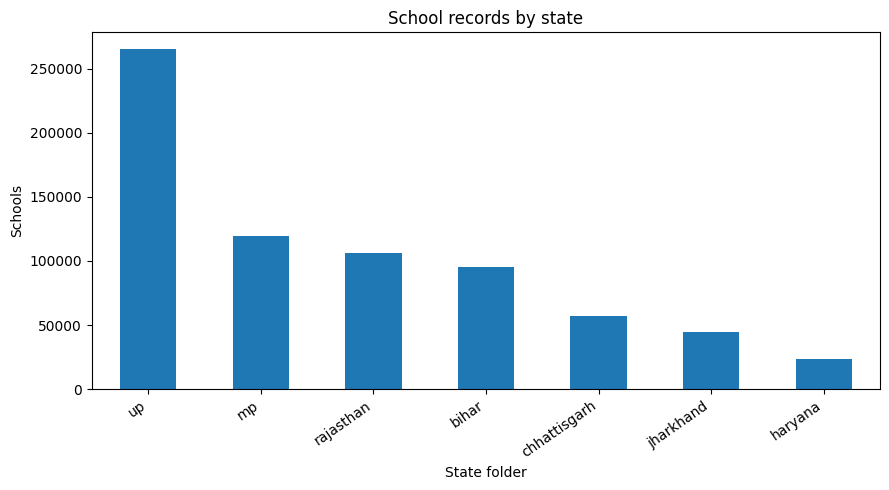

In [11]:
schools_by_state = (master_df.groupby("state").size()
                    .rename("Schools").reset_index()
                    .sort_values("Schools", ascending=False))
display(schools_by_state)
schools_by_state.to_csv(OUTPUT_PATH / "schools_by_state.csv", index=False)
ax = schools_by_state.plot(kind="bar", x="state", y="Schools", legend=False,
                           figsize=(9, 5), title="School records by state")
ax.set_xlabel("State folder"); ax.set_ylabel("Schools")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## Step 12 — Find infrastructure columns

In [12]:
infra_keywords = ["building", "boundary", "classroom", "toilet", "handwash",
                  "water", "rain_water", "electricity", "library", "playground",
                  "ramp", "internet", "kitchen_garden"]
infra_columns = [c for c in master_df.columns
                 if any(k in c.lower() for k in infra_keywords)]
print(f"Found {len(infra_columns)} infrastructure-related columns:")
print(infra_columns)

Found 25 infrastructure-related columns:
['building_status', 'no_building_blocks', 'pucca_building_blocks', 'boundary_wall', 'classrooms_in_good_condition', 'classrooms_needs_minor_repair', 'classrooms_needs_major_repair', 'total_boys_toilet', 'total_boys_func_toilet', 'total_girls_toilet', 'total_girls_func_toilet', 'total_boys_cwsn_toilet', 'total_girls_cwsn_toilet', 'handwash_near_toilet', 'pack_water_yn', 'pack_water_fun_yn', 'rain_water_harvesting', 'handwash_facility_for_meal', 'electricity_availability', 'library_availability', 'playground_available', 'playground_alt_yn', 'availability_ramps', 'internet', 'kitchen_garden_yn']


## Step 13 — Inspect categorical codes before interpreting

In [13]:
code_columns = [c for c in [
    "building_status", "boundary_wall", "electricity_availability",
    "library_availability", "internet", "playground_available",
    "availability_ramps", "pack_water_yn", "handwash_near_toilet"
] if c in master_df.columns]
for col in code_columns:
    print(f"\n{col}")
    display(master_df[col].value_counts(dropna=False).head(15).to_frame("Count"))


building_status


,Count
building_status,
3,462107
1,169106
2,68046
4,7667
5,2184
6,1769
8,716



boundary_wall


,Count
boundary_wall,
1,479265
5,130651
2,49138
7,19703
3,13200
6,9571
8,7161
4,2906



electricity_availability


...

,Count
availability_ramps,
1,553641
2,157954



pack_water_yn


,Count
pack_water_yn,
2,682658
1,28937



handwash_near_toilet


,Count
handwash_near_toilet,
1,657487
2,49008
9,5100


## Step 14 — State-wise code counts and percentages

In [14]:
def code_distribution_by_state(df, column):
    counts = pd.crosstab(df["state"], df[column], dropna=False)
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100).round(2)
    return counts, percentages

for col in ["electricity_availability", "library_availability", "internet"]:
    if col in master_df.columns:
        counts, percentages = code_distribution_by_state(master_df, col)
        print(f"\n{col} — counts"); display(counts)
        print(f"{col} — row percentages"); display(percentages)
        percentages.to_csv(OUTPUT_PATH / f"{col}_state_percentages.csv")


electricity_availability — counts


electricity_availability,1,2,3
state,,,
bihar,94627,524,134
chhattisgarh,53266,2241,1529
haryana,23463,7,9
jharkhand,41355,1823,1200
mp,108518,7718,3458
rajasthan,97405,8046,994
up,235527,26151,3600


electricity_availability — row percentages


electricity_availability,1,2,3
state,,,
bihar,99.31,0.55,0.14
chhattisgarh,93.39,3.93,2.68
haryana,99.93,0.03,0.04
jharkhand,93.19,4.11,2.70
mp,90.66,6.45,2.89
rajasthan,91.51,7.56,0.93
up,88.78,9.86,1.36



library_availability — counts


...

library_availability,1,2
state,,
bihar,60.13,39.87
chhattisgarh,97.67,2.33
haryana,97.98,2.02
jharkhand,93.58,6.42
mp,97.92,2.08
rajasthan,75.32,24.68
up,78.92,21.08



internet — counts


internet,1,2
state,,
bihar,86709,8576
chhattisgarh,44683,12353
haryana,19540,3939
jharkhand,26812,17566
mp,56558,63136
rajasthan,75192,31253
up,133669,131609


internet — row percentages


internet,1,2
state,,
bihar,91.00,9.00
chhattisgarh,78.34,21.66
haryana,83.22,16.78
jharkhand,60.42,39.58
mp,47.25,52.75
rajasthan,70.64,29.36
up,50.39,49.61


## Step 15 — Plot recorded infrastructure codes

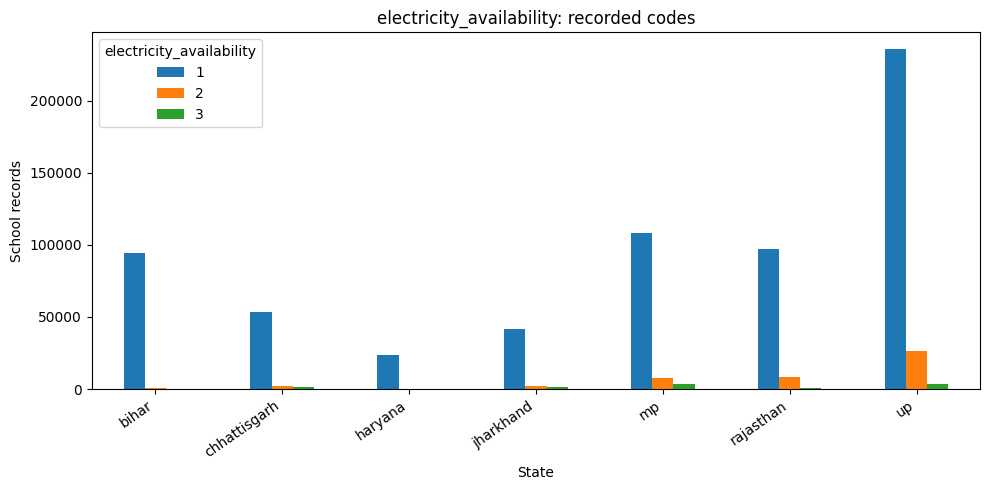

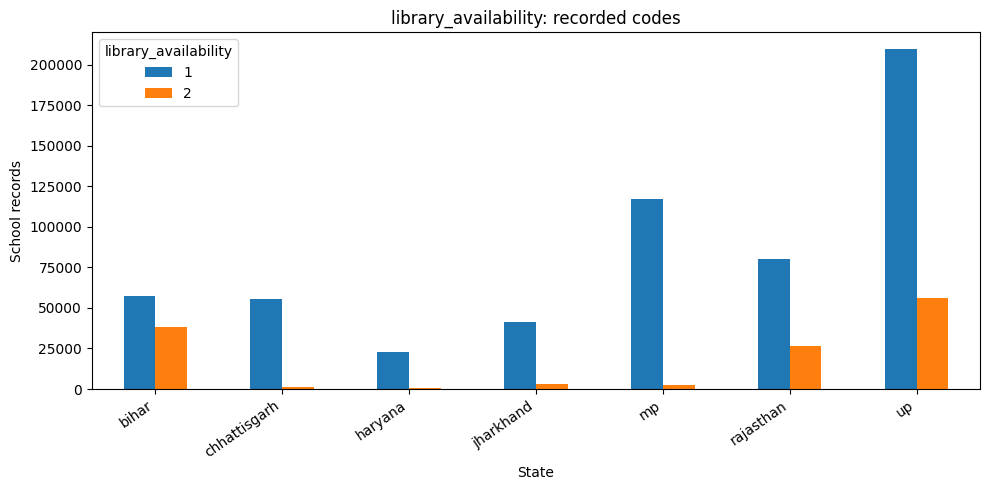

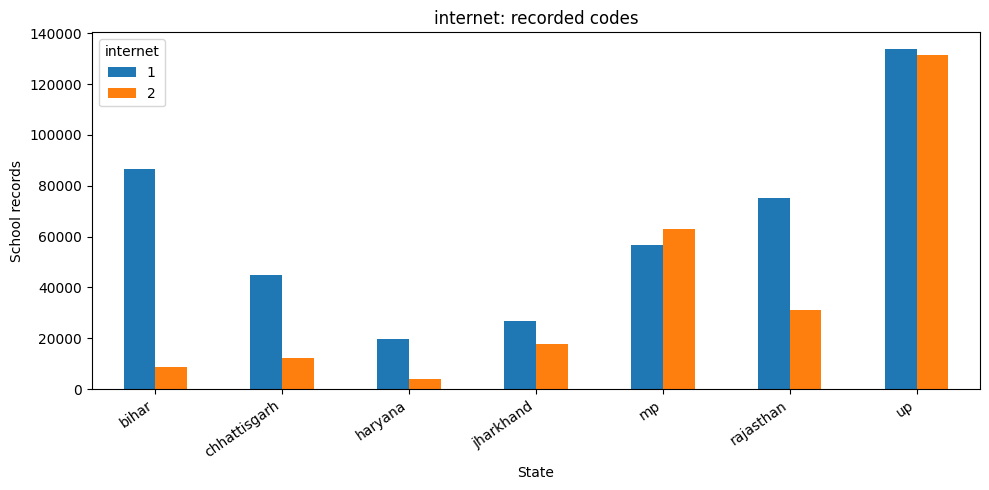

In [15]:
for col in ["electricity_availability", "library_availability", "internet"]:
    if col in master_df.columns:
        counts = pd.crosstab(master_df["state"], master_df[col])
        ax = counts.plot(kind="bar", figsize=(10, 5), title=f"{col}: recorded codes")
        ax.set_xlabel("State"); ax.set_ylabel("School records")
        plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## Step 16 — Discover teacher-related columns

In [16]:
teacher_keywords = ["total_tch", "gen_tch", "sc_tch", "st_tch", "obc_tch", "teacher", "tch"]
teacher_columns = [c for c in master_df.columns
                   if any(k in c.lower() for k in teacher_keywords)]
print(teacher_columns)

['remedial_tch_enrol', 'kitchen_garden_yn', 'total_tch', 'gen_tch', 'sc_tch', 'st_tch', 'obc_tch', 'teacher_involve_non_training_assignment', 'early_childhood_tch']


## Step 17 — Teacher summary statistics

In [17]:
teacher_count_cols = [c for c in ["total_tch", "gen_tch", "sc_tch", "st_tch", "obc_tch"]
                      if c in master_df.columns]
if teacher_count_cols:
    display(master_df[teacher_count_cols].describe().T)
    teacher_summary = master_df.groupby("state")[teacher_count_cols].agg(["mean", "median", "min", "max"])
    display(teacher_summary)
    teacher_summary.to_csv(OUTPUT_PATH / "teacher_summary_by_state.csv")
else:
    print("No expected teacher count columns found.")

,count,mean,std,min,25%,50%,75%,max
total_tch,711595.0,6.547778,7.936586,0.0,3.0,5.0,8.0,398.0
gen_tch,711595.0,2.534473,6.051336,0.0,0.0,1.0,3.0,393.0
sc_tch,711595.0,0.822524,1.268697,0.0,0.0,0.0,1.0,47.0
st_tch,711595.0,0.427742,1.234628,0.0,0.0,0.0,0.0,88.0
obc_tch,711595.0,2.763039,3.187668,0.0,1.0,2.0,4.0,176.0


total_tch                   gen_tch                    sc_tch  \
                   mean median min  max      mean median min  max      mean   
state                                                                         
bihar          7.650155    6.0   0  222  2.723975    2.0   0  177  0.841024   
chhattisgarh   5.053072    3.0   0  226  1.115962    0.0   0  220  0.609089   
haryana       11.399506    7.0   1  332  7.794284    4.0   0  325  1.123174   
jharkhand      4.722746    2.0   0  204  1.328361    0.0   0  184  0.301433   
mp             6.091007    3.0   0  222  2.282403    1.0   0  215  0.772453   
rajasthan      7.451341    6.0   0  398  2.353563    1.0   0  393  1.065029   
up             6.192613    5.0   0  312  2.693955    2.0   0  307  0.847616   

                               st_tch                  obc_tch                  
             median min max      mean median min max      mean median min  max  
state                                                                           
bihar           1.0   0  18  0.094233    0.0   0  34  3.990922    3.0   0   77  
chhattisgarh    0.0   0  22  1.315327    1.0   0  88  2.012694    1.0   0   84  
haryana         1.0   0  21  0.004174    0.0   0   5  2.477874    1.0   0  176  
jharkhand       0.0   0  12  1.041282    0.0   0  58  2.051670    1.0   0   51  
mp              0.0   0  47  0.703903    0.0   0  34  2.332247    1.0   0  101  
rajasthan       1.0   0  17  0.782855    0.0   0  26  3.249894    2.0   0   80  
up              0.0   0  39  0.024454    0.0   0  13  2.626588    2.0   0   73

## Step 18 — Zero-teacher schools by state

In [18]:
if "total_tch" in master_df.columns:
    zero_teacher_summary = master_df.groupby("state").agg(
        Total_schools=("pseudocode", "size"),
        Zero_teacher_schools=("total_tch", lambda s: int((s == 0).sum())),
        Average_teachers=("total_tch", "mean"),
        Median_teachers=("total_tch", "median")
    ).reset_index()
    zero_teacher_summary["Zero_teacher_pct"] = (
        zero_teacher_summary["Zero_teacher_schools"] /
        zero_teacher_summary["Total_schools"] * 100
    ).round(2)
    display(zero_teacher_summary)
    zero_teacher_summary.to_csv(OUTPUT_PATH / "teacher_availability_by_state.csv", index=False)

,state,Total_schools,Zero_teacher_schools,Average_teachers,Median_teachers,Zero_teacher_pct
0,bihar,95285,49,7.650155,6.0,0.05
1,chhattisgarh,57036,169,5.053072,3.0,0.30
2,haryana,23479,0,11.399506,7.0,0.00
3,jharkhand,44378,116,4.722746,2.0,0.26
4,mp,119694,85,6.091007,3.0,0.07
5,rajasthan,106445,414,7.451341,6.0,0.39
6,up,265278,1056,6.192613,5.0,0.40


## Step 19 — Plot average teachers per school

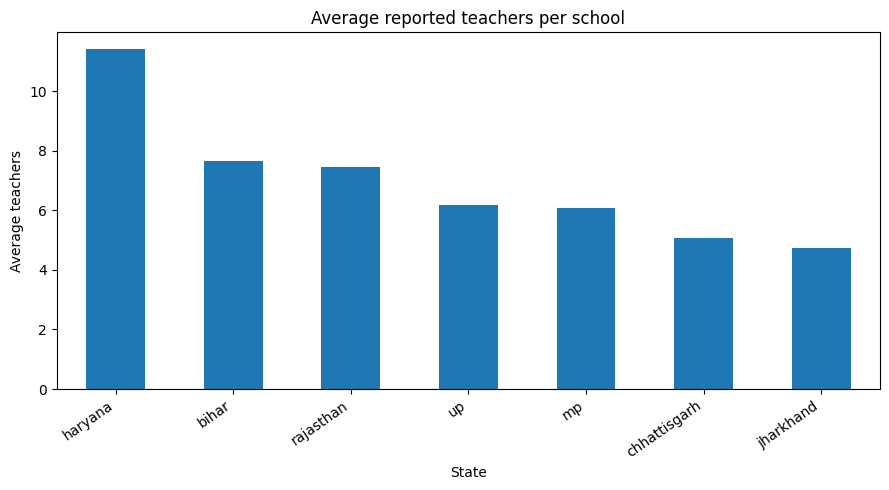

In [19]:
if "total_tch" in master_df.columns:
    teacher_plot = (master_df.groupby("state")["total_tch"].mean()
                    .sort_values(ascending=False).reset_index(name="Average teachers"))
    ax = teacher_plot.plot(kind="bar", x="state", y="Average teachers", legend=False,
                           figsize=(9, 5), title="Average reported teachers per school")
    ax.set_xlabel("State"); ax.set_ylabel("Average teachers")
    plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## Step 20 — Enrollment schema and ID counts

In [20]:
enrollment_keys = [key for key in dataframes if key[1] == "Enrollment"]
print("Enrollment files found:", len(enrollment_keys))
for state, dtype in enrollment_keys:
    df = dataframes[(state, dtype)]
    print(f"{state}: rows={len(df):,}, columns={len(df.columns)}, unique IDs={df['pseudocode'].nunique():,}")
if enrollment_keys:
    sample_enrollment_df = dataframes[enrollment_keys[0]]
    print("Sample columns:", sample_enrollment_df.columns.tolist())

Enrollment files found: 7
bihar: rows=972,166, columns=42, unique IDs=95,285
chhattisgarh: rows=421,820, columns=42, unique IDs=56,887
haryana: rows=240,115, columns=42, unique IDs=23,479
jharkhand: rows=433,493, columns=42, unique IDs=44,253
mp: rows=1,078,230, columns=42, unique IDs=119,694
rajasthan: rows=1,084,857, columns=42, unique IDs=106,305
up: rows=2,491,171, columns=42, unique IDs=264,965
Sample columns: ['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b', 'c7_g', 'c7_t', 'c8_b', 'c8_g', 'c8_t', 'c9_b', 'c9_g', 'c9_t', 'c10_b', 'c10_g', 'c10_t', 'c11_b', 'c11_g', 'c11_t', 'c12_b', 'c12_g', 'c12_t']


## Step 21 — Inspect `item_id` values

In [21]:
if enrollment_keys:
    sample_enrollment_df = dataframes[enrollment_keys[0]]
    print("item_group values:", sample_enrollment_df["item_group"].dropna().unique())
    display(sample_enrollment_df[["pseudocode", "item_group", "item_id"]].head(25))
    display(sample_enrollment_df["item_id"].value_counts().sort_index().to_frame("Record count"))

item_group values: [8]


,pseudocode,item_group,item_id
0,1000031,8,4
1,1000031,8,5
2,1000031,8,6
3,1000031,8,7
4,1000031,8,8
5,1000031,8,9
6,1000031,8,10
7,1000031,8,11
8,1000031,8,12
9,1000031,8,13


,Record count
item_id,
3,6100
4,28463
5,78617
6,82582
7,83253
8,83822
9,84353
10,84577
11,83057


## Step 22 — Validate recorded total fields

In [22]:
if enrollment_keys:
    df = sample_enrollment_df
    checks = []
    for cls in ["cpp"] + [f"c{i}" for i in range(1, 13)]:
        b, g, t = f"{cls}_b", f"{cls}_g", f"{cls}_t"
        if all(c in df.columns for c in [b, g, t]):
            boys = pd.to_numeric(df[b], errors="coerce").fillna(0)
            girls = pd.to_numeric(df[g], errors="coerce").fillna(0)
            total = pd.to_numeric(df[t], errors="coerce").fillna(0)
            checks.append({
                "Class": cls, "Boys sum": int(boys.sum()),
                "Girls sum": int(girls.sum()), "Boys + girls": int((boys + girls).sum()),
                "Recorded _t sum": int(total.sum()),
                "Rows total != boys+girls": int((total != boys + girls).sum())
            })
    display(pd.DataFrame(checks))

,Class,Boys sum,Girls sum,Boys + girls,Recorded _t sum,Rows total != boys+girls
0,cpp,215048,139852,354900,9,34184
1,c1,843576,764772,1608348,40,288677
2,c2,841319,780835,1622154,14,308467
3,c3,944819,889908,1834727,18,340331
4,c4,1084979,1027137,2112116,26,373730
5,c5,1151811,1126749,2278560,25,388234
6,c6,1008530,993892,2002422,25,236506
7,c7,985852,1001781,1987633,12,233201
8,c8,894162,917632,1811794,9,226182
9,c9,658787,706850,1365637,1,79608


## Step 23 — Aggregate enrollment to one row per school (provisional)

In [23]:
class_columns = ["cpp"] + [f"c{i}" for i in range(1, 13)]
gender_columns = [f"{cls}_{gender}" for cls in class_columns for gender in ["b", "g"]]
enrollment_parts = []

for state, dtype in enrollment_keys:
    df = dataframes[(state, dtype)].copy()
    if "pseudocode" not in df.columns:
        print("Skipping; no pseudocode:", state)
        continue
    for col in gender_columns:
        if col not in df.columns:
            df[col] = 0
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    school_df = df.groupby("pseudocode", as_index=False)[gender_columns].sum()
    school_df["pseudocode"] = school_df["pseudocode"].astype(str)
    school_df["state_enrollment_source"] = state
    for cls in class_columns:
        school_df[f"{cls}_total"] = school_df[f"{cls}_b"] + school_df[f"{cls}_g"]
    school_df["total_enrollment"] = school_df[[f"{cls}_total" for cls in class_columns]].sum(axis=1)
    enrollment_parts.append(school_df)

enrollment_school_df = pd.concat(enrollment_parts, ignore_index=True) if enrollment_parts else pd.DataFrame()
print("Provisional enrollment shape:", enrollment_school_df.shape)
if not enrollment_school_df.empty:
    print("Unique IDs:", enrollment_school_df["pseudocode"].nunique())
    print("Duplicate IDs:", enrollment_school_df["pseudocode"].duplicated().sum())
    display(enrollment_school_df[["state_enrollment_source", "pseudocode", "total_enrollment"]].head())

Provisional enrollment shape: (710868, 42)
Unique IDs: 710868
Duplicate IDs: 0


,state_enrollment_source,pseudocode,total_enrollment
0,bihar,1000031,293
1,bihar,1000035,220
2,bihar,1000049,159
3,bihar,1000072,490
4,bihar,1000075,134


## Step 24 — Check enrollment ID overlap

In [24]:
if not enrollment_school_df.empty:
    master_ids = set(master_df["pseudocode"].astype(str))
    enrollment_ids = set(enrollment_school_df["pseudocode"].astype(str))
    print("Master schools:", len(master_ids))
    print("Enrollment schools:", len(enrollment_ids))
    print("In both:", len(master_ids & enrollment_ids))
    print("Master without enrollment:", len(master_ids - enrollment_ids))
    print("Enrollment absent from master:", len(enrollment_ids - master_ids))

Master schools: 711595
Enrollment schools: 710868
In both: 710868
Master without enrollment: 727
Enrollment absent from master: 0


## Step 25 — Merge enrollment without duplicating schools

In [25]:
if not enrollment_school_df.empty:
    enrollment_for_merge = enrollment_school_df.drop(columns=["state_enrollment_source"], errors="ignore").copy()
    enrollment_for_merge["pseudocode"] = enrollment_for_merge["pseudocode"].astype(str)
    master_df["pseudocode"] = master_df["pseudocode"].astype(str)

    existing = [c for c in enrollment_for_merge.columns
                if c != "pseudocode" and c in master_df.columns]
    master_df = master_df.drop(columns=existing)

    master_df = master_df.merge(
        enrollment_for_merge, on="pseudocode", how="left",
        validate="one_to_one", indicator="_enrollment_merge"
    )
    print("Merge status:"); display(master_df["_enrollment_merge"].value_counts())
    print("Rows:", len(master_df), "| unique IDs:", master_df["pseudocode"].nunique())
    print("Missing enrollment:", int(master_df["total_enrollment"].isna().sum()))
    master_df.drop(columns="_enrollment_merge", inplace=True)

Merge status:


,count
_enrollment_merge,
both,710868
left_only,727
right_only,0


Rows: 711595 | unique IDs: 711595
Missing enrollment: 727


## Step 26 — Inspect provisional enrollment totals

In [26]:
if "total_enrollment" in master_df.columns:
    display(master_df["total_enrollment"].describe().to_frame())
    print("Zero totals:", int((master_df["total_enrollment"] == 0).sum()))
    print("Missing totals:", int(master_df["total_enrollment"].isna().sum()))
    cols = [c for c in ["state", "district", "pseudocode", "total_enrollment"] if c in master_df.columns]
    display(master_df[cols].dropna(subset=["total_enrollment"])
            .sort_values("total_enrollment", ascending=False).head(20))
    print("Schools above 1,000 (provisional):", int((master_df["total_enrollment"] > 1000).sum()))

,total_enrollment
count,710868.000000
mean,159.928011
std,249.251679
min,1.000000
25%,39.000000
50%,83.000000
75%,180.000000
max,8862.000000


Zero totals: 0
Missing totals: 727


,state,district,pseudocode,total_enrollment
452125,up,LUCKNOW,4899767,8862.0
656963,up,LUCKNOW,2270539,7176.0
575347,up,LUCKNOW,7563729,6901.0
682598,up,SULTANPUR,9982093,6618.0
603189,up,LUCKNOW,5111692,6526.0
425206,rajasthan,SIKAR,5448351,6323.0
196675,jharkhand,DHANBAD,7316287,6298.0
357237,rajasthan,SIKAR,8267950,6177.0
583327,up,KHERI,9171071,6165.0
120110,chhattisgarh,DURG,3978861,6140.0


Schools above 1,000 (provisional): 10893


## Step 27 — Save merged master separately

In [27]:
merged_output = OUTPUT_PATH / "school_level_master_with_provisional_enrollment.csv"
master_df.to_csv(merged_output, index=False)
print("Saved:", merged_output)

Saved: /content/drive/MyDrive/India_School_Education_Data/analysis_outputs/school_level_master_with_provisional_enrollment.csv


## Step 28 — Optional infrastructure availability percentages

In [28]:
# Confirm these code meanings against the exact AY 2025–26 codebook before switching this on.
CODEBOOK_CONFIRMED = False
if CODEBOOK_CONFIRMED:
    availability_rows = []
    for state, group in master_df.groupby("state"):
        row = {"State": state, "Total schools": len(group)}
        if "electricity_availability" in group:
            row["Electricity code 1 (%)"] = (group["electricity_availability"] == 1).mean() * 100
        if "library_availability" in group:
            row["Library code 1 (%)"] = (group["library_availability"] == 1).mean() * 100
        if "internet" in group:
            row["Internet code 1 (%)"] = (group["internet"] == 1).mean() * 100
        availability_rows.append(row)
    availability_df = pd.DataFrame(availability_rows).round(2)
    display(availability_df)
    availability_df.to_csv(OUTPUT_PATH / "infrastructure_availability_by_state.csv", index=False)
else:
    print("Not calculated: first confirm field codes in the official codebook.")

Not calculated: first confirm field codes in the official codebook.


## Step 29 — Install Graphviz

In [29]:
!apt-get -qq update
!apt-get -qq install graphviz
!pip -q install graphviz

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## Step 30 — Graphviz workflow diagram

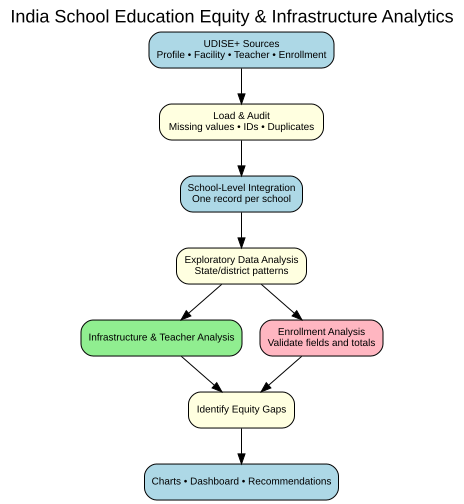

Saved workflow diagram.


In [30]:
from graphviz import Digraph

workflow = Digraph("Education_Analytics_Workflow", format="png")
workflow.attr(rankdir="TB", labelloc="t",
              label="India School Education Equity & Infrastructure Analytics",
              fontsize="18", fontname="Arial")
workflow.attr("node", shape="box", style="rounded,filled", fontname="Arial", fontsize="10")
workflow.node("A", "UDISE+ Sources\nProfile • Facility • Teacher • Enrollment", fillcolor="lightblue")
workflow.node("B", "Load & Audit\nMissing values • IDs • Duplicates", fillcolor="lightyellow")
workflow.node("C", "School-Level Integration\nOne record per school", fillcolor="lightblue")
workflow.node("D", "Exploratory Data Analysis\nState/district patterns", fillcolor="lightyellow")
workflow.node("E", "Infrastructure & Teacher Analysis", fillcolor="lightgreen")
workflow.node("F", "Enrollment Analysis\nValidate fields and totals", fillcolor="lightpink")
workflow.node("G", "Identify Equity Gaps", fillcolor="lightyellow")
workflow.node("H", "Charts • Dashboard • Recommendations", fillcolor="lightblue")
workflow.edges([("A","B"),("B","C"),("C","D"),("D","E"),("D","F"),("E","G"),("F","G"),("G","H")])
display(workflow)
workflow.render(str(OUTPUT_PATH / "education_analytics_workflow"), cleanup=True)
print("Saved workflow diagram.")

## Step 31 — Graphviz data integration diagram

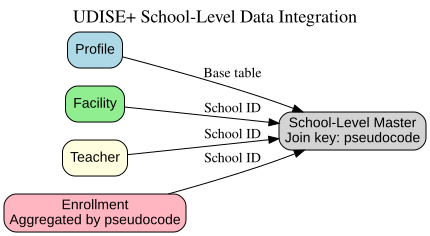

Saved data integration diagram.


In [31]:
integration = Digraph("Data_Integration", format="png")
integration.attr(rankdir="LR", labelloc="t",
                 label="UDISE+ School-Level Data Integration", fontsize="18")
integration.attr("node", shape="box", style="rounded,filled", fontname="Arial")
integration.node("P", "Profile", fillcolor="lightblue")
integration.node("F", "Facility", fillcolor="lightgreen")
integration.node("T", "Teacher", fillcolor="lightyellow")
integration.node("E", "Enrollment\nAggregated by pseudocode", fillcolor="lightpink")
integration.node("M", "School-Level Master\nJoin key: pseudocode", fillcolor="lightgrey")
integration.edge("P", "M", label="Base table")
integration.edge("F", "M", label="School ID")
integration.edge("T", "M", label="School ID")
integration.edge("E", "M", label="School ID")
display(integration)
integration.render(str(OUTPUT_PATH / "education_data_integration"), cleanup=True)
print("Saved data integration diagram.")

## Step 32 — Review saved output files

In [32]:
output_files = sorted(p.name for p in OUTPUT_PATH.iterdir() if p.is_file())
display(pd.DataFrame({"Output file": output_files}))

,Output file
0,dataset_quality_summary.csv
1,education_analytics_workflow.png
2,education_data_integration.png
3,electricity_availability_state_percentages.csv
4,file_inventory.csv
5,internet_state_percentages.csv
6,library_availability_state_percentages.csv
7,master_missingness.csv
8,merge_log.csv
9,school_id_checks.csv


## Step 33 — Reproducibility checks

In [33]:
print("Master shape:", master_df.shape)
print("Unique school IDs:", master_df["pseudocode"].nunique())
print("Duplicate school IDs:", int(master_df["pseudocode"].duplicated().sum()))
print("States:", sorted(master_df["state"].dropna().unique()))
print("Output directory exists:", OUTPUT_PATH.exists())

Master shape: (711595, 207)
Unique school IDs: 711595
Duplicate school IDs: 0
States: ['bihar', 'chhattisgarh', 'haryana', 'jharkhand', 'mp', 'rajasthan', 'up']
Output directory exists: True


## Step 34 — BADIR framing for the report

- **Business understanding:** Compare school infrastructure and teacher availability across seven states to identify possible resource gaps.
- **Analytics question:** Which states/districts have lower recorded availability of selected school facilities?
- **Data:** UDISE+ Profile, Facility, Teacher and Enrollment CSV files.
- **Method:** Data-quality audit, school-ID validation, joins, descriptive statistics, state-wise comparisons, charts, and enrollment-definition checks.
- **Interpretation:** School counts describe coverage, not school quality; availability does not guarantee functionality or use; associations do not establish causation.

## Step 35 — Hypotheses to evaluate after validation

1. Recorded internet availability differs across states.
2. Recorded electricity availability differs across states.
3. Reported teacher counts per school differ across states.
4. Verified facility indicators differ between rural and urban schools, if coding is confirmed.
5. Teacher counts and infrastructure indicators may be associated, without implying causation.

## Step 36 — Evidence-based recommendations template

- Prioritize follow-up data verification where records are missing or inconsistent.
- Identify districts with low verified facility availability for targeted audits.
- Review schools reporting zero teachers or unusually high teacher/enrollment values.
- Distinguish facility availability from functionality, use, and learning outcomes.
- Report denominator, year, coverage, and limitations on every chart.

## Step 37 — Save a run summary

In [34]:
run_summary = pd.Series({
    "States requested": len(STATES),
    "Files loaded": len(dataframes),
    "Master rows": len(master_df),
    "Master columns": len(master_df.columns),
    "Unique school IDs": int(master_df["pseudocode"].nunique()),
    "Duplicate school IDs": int(master_df["pseudocode"].duplicated().sum()),
    "Enrollment merged": "total_enrollment" in master_df.columns,
    "Enrollment totals provisional": "total_enrollment" in master_df.columns
}, name="Value")
display(run_summary.to_frame())
run_summary.to_csv(OUTPUT_PATH / "run_summary.csv", header=True)

,Value
States requested,7
Files loaded,28
Master rows,711595
Master columns,207
Unique school IDs,711595
Duplicate school IDs,0
Enrollment merged,True
Enrollment totals provisional,True


## Steps 38–44 — Compact follow-up diagnostics
These cells summarize the earlier follow-up checks without rereading the files or repeating the merge.

In [35]:
# Enrollment completeness and outlier checks
if "total_enrollment" in master_df.columns:
    print("Schools with enrollment:", int(master_df["total_enrollment"].notna().sum()))
    print("Schools missing enrollment:", int(master_df["total_enrollment"].isna().sum()))
    print("Median provisional enrollment:", master_df["total_enrollment"].median())
    print("Maximum provisional enrollment:", master_df["total_enrollment"].max())
    print("Schools above 1,000:", int((master_df["total_enrollment"] > 1000).sum()))
    largest = master_df.loc[master_df["total_enrollment"].idxmax(),
                            [c for c in ["state", "district", "pseudocode", "total_enrollment"]
                             if c in master_df.columns]]
    display(largest.to_frame("Largest provisional value"))
else:
    print("Enrollment has not been merged. Complete Steps 20–25 after resolving duplicate IDs.")

Schools with enrollment: 710868
Schools missing enrollment: 727
Median provisional enrollment: 83.0
Maximum provisional enrollment: 8862.0
Schools above 1,000: 10893


,Largest provisional value
state,up
district,LUCKNOW
pseudocode,4899767
total_enrollment,8862.0


## Before submitting

- [ ] Confirm all expected files exist (7 states × 4 data types).
- [ ] Investigate duplicates; never drop duplicate `pseudocode` rows automatically.
- [ ] Verify code definitions against the AY 2025–26 UDISE+ data dictionary.
- [ ] Verify whether summing across `item_id` is valid before using enrollment totals as official counts.
- [ ] Treat missing enrollment as missing, not zero.
- [ ] Use percentages with clear denominators for state comparisons.
- [ ] Source CSVs are unchanged; derived outputs are saved in `analysis_outputs`.
- [ ] After a runtime restart, run cells top to bottom.